In [1]:
#import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
# load dataset
df = pd.read_csv("news.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df["label"].value_counts())

Dataset shape: (6335, 4)
   Unnamed: 0                                              title  \
0        8476                       You Can Smell Hillary’s Fear   
1       10294  Watch The Exact Moment Paul Ryan Committed Pol...   
2        3608        Kerry to go to Paris in gesture of sympathy   
3       10142  Bernie supporters on Twitter erupt in anger ag...   
4         875   The Battle of New York: Why This Primary Matters   

                                                text label  
0  Daniel Greenfield, a Shillman Journalism Fello...  FAKE  
1  Google Pinterest Digg Linkedin Reddit Stumbleu...  FAKE  
2  U.S. Secretary of State John F. Kerry said Mon...  REAL  
3  — Kaydee King (@KaydeeKing) November 9, 2016 T...  FAKE  
4  It's primary day in New York and front-runners...  REAL  
label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [3]:
# data preprocessing
df = df.dropna(subset=["label"]).copy()

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

df["content"] = (
    df["title"].astype(str) + " " +
    df["text"].astype(str)
).str.strip()

df = df[df["content"] != ""]
df = df.drop_duplicates(subset=["content"])

X = df["content"]
y = df["label"].str.strip().str.upper()

print("Total articles:", len(df))
print("Labels:", y.unique())
print("Missing values:", X.isna().sum())

Total articles: 6306
Labels: <ArrowStringArray>
['FAKE', 'REAL']
Length: 2, dtype: str
Missing values: 0


In [4]:
#split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5044
Testing samples: 1262


In [5]:
#build the TF-IDF model
tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (5044, 50000)
Testing feature shape: (1262, 50000)


In [6]:
#training
tfidf_model = LogisticRegression(max_iter=1000)

tfidf_model.fit(X_train_tfidf, y_train)

tfidf_predictions = tfidf_model.predict(X_test_tfidf)

print("TF-IDF Accuracy:",
      f"{accuracy_score(y_test, tfidf_predictions):.2%}")

print(classification_report(y_test, tfidf_predictions))

TF-IDF Accuracy: 92.63%
              precision    recall  f1-score   support

        FAKE       0.92      0.94      0.93       631
        REAL       0.94      0.91      0.93       631

    accuracy                           0.93      1262
   macro avg       0.93      0.93      0.93      1262
weighted avg       0.93      0.93      0.93      1262



In [7]:
#Hashing vectorizer model
hash_vectorizer = HashingVectorizer(
    n_features=2**18,
    alternate_sign=False,
    norm="l2",
    stop_words="english",
    ngram_range=(1, 2),
    dtype=np.float32
)

X_train_hash = hash_vectorizer.transform(X_train)
X_test_hash = hash_vectorizer.transform(X_test)

print("Training feature shape:", X_train_hash.shape)
print("Testing feature shape:", X_test_hash.shape)

Training feature shape: (5044, 262144)
Testing feature shape: (1262, 262144)


In [8]:
#training
hash_model = LogisticRegression(max_iter=1000)

hash_model.fit(X_train_hash, y_train)

hash_predictions = hash_model.predict(X_test_hash)

print("Hashing Accuracy:",
      f"{accuracy_score(y_test, hash_predictions):.2%}")

print(classification_report(y_test, hash_predictions))

Hashing Accuracy: 89.94%
              precision    recall  f1-score   support

        FAKE       0.88      0.92      0.90       631
        REAL       0.92      0.88      0.90       631

    accuracy                           0.90      1262
   macro avg       0.90      0.90      0.90      1262
weighted avg       0.90      0.90      0.90      1262



  Vectorizer  Accuracy
0     TF-IDF  0.926307
1    Hashing  0.899366


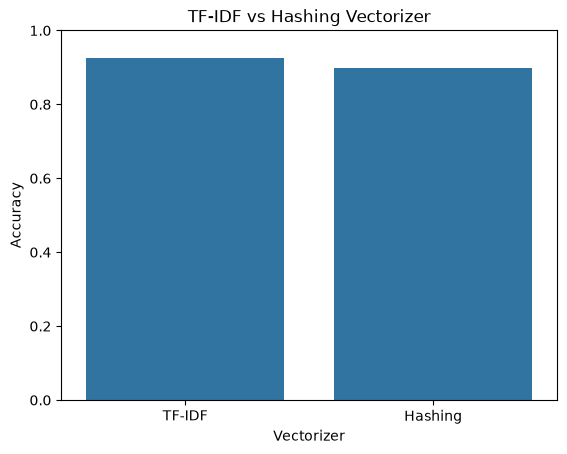

In [9]:
# Compare TF-IDF and Hashing Vectorizer
results = pd.DataFrame({
    "Vectorizer": ["TF-IDF", "Hashing"],
    "Accuracy": [
        accuracy_score(y_test, tfidf_predictions),
        accuracy_score(y_test, hash_predictions)
    ]
})

print(results)

sns.barplot(data=results, x="Vectorizer", y="Accuracy")
plt.ylim(0, 1)
plt.title("TF-IDF vs Hashing Vectorizer")
plt.ylabel("Accuracy")
plt.show()

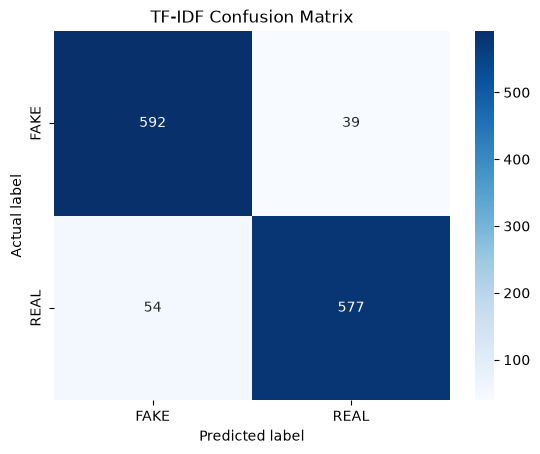

In [10]:
 # Confusion matrix
cm = confusion_matrix(
    y_test,
    tfidf_predictions,
    labels=["FAKE", "REAL"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["FAKE", "REAL"],
    yticklabels=["FAKE", "REAL"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("TF-IDF Confusion Matrix")
plt.show()

In [1]:
#import all libraries
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer

from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, mean_absolute_error, mean_squared_error, r2_score
)

df = pd.read_csv("news.csv")

df = df.dropna(subset=["label"]).copy()
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")
df["content"] = df["title"] + " " + df["text"]
df["label"] = df["label"].str.strip().str.upper()

df = df[df["label"].isin(["REAL", "FAKE"])]
df = df[df["content"].str.strip() != ""]
df = df.drop_duplicates(subset=["content"])

X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 5044
Testing: 1262


In [2]:
# Apply TF-IDF and Hashing Vectorizer
tfidf = TfidfVectorizer(
    max_features=30000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

hashing = HashingVectorizer(
    n_features=2**18,
    alternate_sign=False,
    norm="l2",
    stop_words="english",
    ngram_range=(1, 2),
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

X_train_hash = hashing.transform(X_train)
X_test_hash = hashing.transform(X_test)

print("TF-IDF shape:", X_train_tfidf.shape)
print("Hashing shape:", X_train_hash.shape)

TF-IDF shape: (5044, 30000)
Hashing shape: (5044, 262144)


In [3]:
# Define the six classification algorithms
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Linear SVM": LinearSVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=30,
        random_state=42, n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=30, random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5, algorithm="brute"
    )
}

In [4]:
# Train and compare all classifiers
results = []
trained_models = {}

vectorizers = {
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Hashing": (X_train_hash, X_test_hash)
}

for vectorizer_name, (Xtr, Xte) in vectorizers.items():
    for model_name, model in models.items():
        start = time.time()

        try:
            model.fit(Xtr, y_train)
            predictions = model.predict(Xte)

            results.append({
                "Vectorizer": vectorizer_name,
                "Algorithm": model_name,
                "Accuracy": accuracy_score(y_test, predictions),
                "Precision": precision_score(
                    y_test, predictions, pos_label="FAKE",
                    zero_division=0
                ),
                "Recall": recall_score(
                    y_test, predictions, pos_label="FAKE",
                    zero_division=0
                ),
                "F1 Score": f1_score(
                    y_test, predictions, pos_label="FAKE",
                    zero_division=0
                ),
                "Time (seconds)": round(time.time() - start, 2)
            })

            trained_models[(vectorizer_name, model_name)] = model

            print(
                vectorizer_name, "|", model_name,
                "| Accuracy:",
                f"{accuracy_score(y_test, predictions):.2%}"
            )

        except Exception as e:
            print("Error:", vectorizer_name, model_name, e)

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1 Score", ascending=False)

display(results_df)

TF-IDF | Multinomial Naive Bayes | Accuracy: 89.38%
TF-IDF | Bernoulli Naive Bayes | Accuracy: 83.44%
TF-IDF | Linear SVM | Accuracy: 93.03%
TF-IDF | Random Forest | Accuracy: 89.78%
TF-IDF | Decision Tree | Accuracy: 80.03%
TF-IDF | KNN | Accuracy: 85.42%
Hashing | Multinomial Naive Bayes | Accuracy: 83.36%
Hashing | Bernoulli Naive Bayes | Accuracy: 79.24%
Hashing | Linear SVM | Accuracy: 92.31%
Hashing | Random Forest | Accuracy: 87.72%
Hashing | Decision Tree | Accuracy: 80.59%
Hashing | KNN | Accuracy: 82.25%


,Vectorizer,Algorithm,Accuracy,Precision,Recall,F1 Score,Time (seconds)
2,TF-IDF,Linear SVM,0.930269,0.923557,0.938193,0.930818,0.39
8,Hashing,Linear SVM,0.923138,0.917188,0.930269,0.923682,0.93
3,TF-IDF,Random Forest,0.897781,0.884969,0.914422,0.899454,2.23
0,TF-IDF,Multinomial Naive Bayes,0.893819,0.905383,0.879556,0.892283,0.12
9,Hashing,Random Forest,0.877179,0.866154,0.892235,0.879001,4.26
1,TF-IDF,Bernoulli Naive Bayes,0.834390,0.776903,0.938193,0.849964,0.16
5,TF-IDF,KNN,0.854200,0.919325,0.776545,0.841924,0.80
7,Hashing,Bernoulli Naive Bayes,0.792393,0.739922,0.901743,0.812857,0.28
10,Hashing,Decision Tree,0.805864,0.803459,0.809826,0.806630,64.36
6,Hashing,Multinomial Naive Bayes,0.833597,0.966741,0.690967,0.805915,0.20


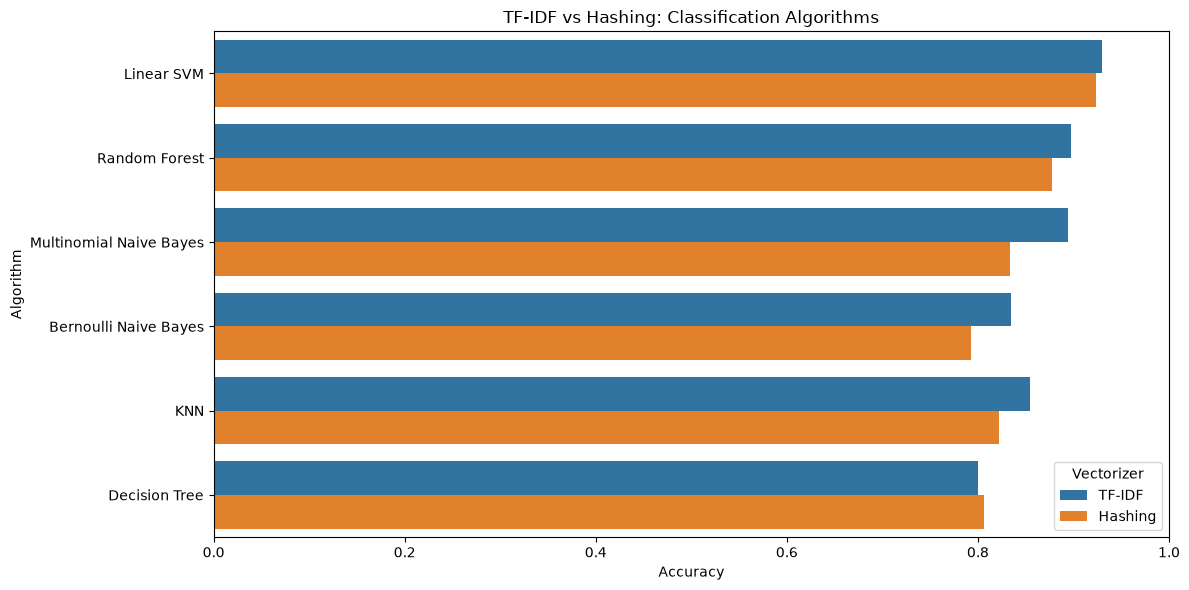

In [5]:
# Visualize the results
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Algorithm",
    hue="Vectorizer"
)

plt.title("TF-IDF vs Hashing: Classification Algorithms")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

